In [46]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = df.copy()

coluna_chuva = "PRECIPITAÇÃO TOTAL, HORÁRIO (mm)"

df[coluna_chuva] = pd.to_numeric(df[coluna_chuva], errors="coerce")

df = df.dropna(subset=[coluna_chuva])
df = df[df[coluna_chuva] >= 0]

df["classe_chuva"] = pd.cut(
    df[coluna_chuva],
    bins=[-0.001, 0, 5, 20, 50, np.inf],
    labels=[0, 1, 2, 3, 4]
)

df["classe_chuva"] = df["classe_chuva"].astype(int)

print(df["classe_chuva"].value_counts().sort_index())


classe_chuva
0    28786
1     4210
2      292
3       24
Name: count, dtype: int64


In [47]:

features = [
    "PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",
    "TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",
    "TEMPERATURA DO PONTO DE ORVALHO (°C)",
    "UMIDADE RELATIVA DO AR, HORARIA (%)",
    "VENTO, DIREÇÃO HORARIA (gr) (° (gr))",
    "VENTO, RAJADA MAXIMA (m/s)",
    "VENTO, VELOCIDADE HORARIA (m/s)"
]

target = "classe_chuva"


In [48]:

df["datetime"] = pd.to_datetime(df["datetime"], errors="coerce")

df = df.dropna(subset=["datetime"])
df = df.sort_values("datetime").reset_index(drop=True)

df["hora"] = df["datetime"].dt.hour
df["mes"] = df["datetime"].dt.month

df["hora_sin"] = np.sin(2 * np.pi * df["hora"] / 24)
df["hora_cos"] = np.cos(2 * np.pi * df["hora"] / 24)

df["mes_sin"] = np.sin(2 * np.pi * df["mes"] / 12)
df["mes_cos"] = np.cos(2 * np.pi * df["mes"] / 12)

coluna_direcao = "VENTO, DIREÇÃO HORARIA (gr) (° (gr))"

direcao = pd.to_numeric(df[coluna_direcao], errors="coerce")

df["vento_dir_sin"] = np.sin(np.radians(direcao))
df["vento_dir_cos"] = np.cos(np.radians(direcao))

features.remove(coluna_direcao)

features.extend([
    "hora_sin",
    "hora_cos",
    "mes_sin",
    "mes_cos",
    "vento_dir_sin",
    "vento_dir_cos"
])


In [49]:

X = df[features].copy()
y = df[target].copy()

ponto_divisao = int(len(df) * 0.8)

X_train = X.iloc[:ponto_divisao].copy()
X_test = X.iloc[ponto_divisao:].copy()

y_train = y.iloc[:ponto_divisao].copy()
y_test = y.iloc[ponto_divisao:].copy()

print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)

print("\nPeríodo de treinamento:")
print(df["datetime"].iloc[0], "até", df["datetime"].iloc[ponto_divisao - 1])

print("\nPeríodo de teste:")
print(df["datetime"].iloc[ponto_divisao], "até", df["datetime"].iloc[-1])


Treinamento: (26649, 12)
Teste: (6663, 12)

Período de treinamento:
2018-01-03 12:00:00 até 2021-02-04 12:00:00

Período de teste:
2021-02-04 13:00:00 até 2021-11-12 06:00:00


In [50]:

X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

medianas = X_train.median()

X_train = X_train.fillna(medianas)
X_test = X_test.fillna(medianas)

print("Valores ausentes no treino:")
print(X_train.isna().sum())

print("\nValores ausentes no teste:")
print(X_test.isna().sum())


Valores ausentes no treino:
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)    0
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)             0
TEMPERATURA DO PONTO DE ORVALHO (°C)                     0
UMIDADE RELATIVA DO AR, HORARIA (%)                      0
VENTO, RAJADA MAXIMA (m/s)                               0
VENTO, VELOCIDADE HORARIA (m/s)                          0
hora_sin                                                 0
hora_cos                                                 0
mes_sin                                                  0
mes_cos                                                  0
vento_dir_sin                                            0
vento_dir_cos                                            0
dtype: int64

Valores ausentes no teste:
PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)    0
TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)             0
TEMPERATURA DO PONTO DE ORVALHO (°C)                     0
UMIDADE RELATIVA DO AR, HORARIA (%)           

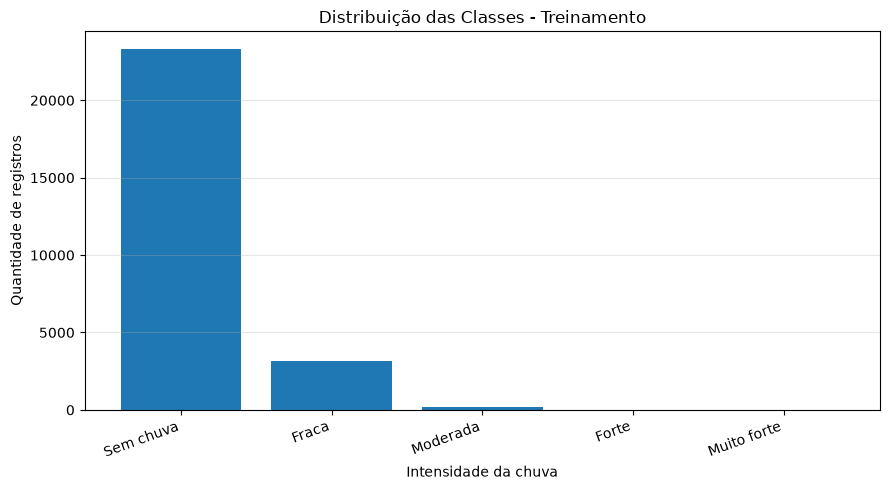

In [51]:

distribuicao = y_train.value_counts().sort_index()

nomes_classes = [
    "Sem chuva",
    "Fraca",
    "Moderada",
    "Forte",
    "Muito forte"
]

plt.figure(figsize=(9, 5))

plt.bar(
    nomes_classes,
    [distribuicao.get(i, 0) for i in range(5)]
)

plt.title("Distribuição das Classes - Treinamento")
plt.xlabel("Intensidade da chuva")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [52]:
import re

# Criar cópias dos conjuntos de treinamento e teste
X_train_lgbm = X_train.copy()
X_test_lgbm = X_test.copy()

# Simplificar os nomes das colunas
def limpar_nome(nome):
    nome = re.sub(r"[^a-zA-Z0-9_]", "_", nome)
    nome = re.sub(r"_+", "_", nome)
    return nome.strip("_")

X_train_lgbm.columns = [limpar_nome(col) for col in X_train_lgbm.columns]
X_test_lgbm.columns = [limpar_nome(col) for col in X_test_lgbm.columns]


In [53]:
from lightgbm import LGBMClassifier

modelo_lgbm = LGBMClassifier(
    objective="multiclass",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

modelo_lgbm.fit(X_train_lgbm, y_train)

print("Modelo LightGBM treinado com sucesso!")

Modelo LightGBM treinado com sucesso!


In [54]:
y_pred = modelo_lgbm.predict(X_test_lgbm)

y_prob = modelo_lgbm.predict_proba(X_test_lgbm)

print("Previsões realizadas com sucesso!")

Previsões realizadas com sucesso!


In [55]:

comparacao = pd.DataFrame({
    "Classe real": y_test.values,
    "Classe prevista": y_pred
})

comparacao.head(20)


,Classe real,Classe prevista
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,0,0
9,0,0


In [56]:

from sklearn.metrics import accuracy_score, balanced_accuracy_score

acuracia = accuracy_score(y_test, y_pred)
acuracia_balanceada = balanced_accuracy_score(y_test, y_pred)

print(f"Acurácia: {acuracia:.4f} ({acuracia * 100:.2f}%)")
print(f"Acurácia balanceada: {acuracia_balanceada:.4f} ({acuracia_balanceada * 100:.2f}%)")


Acurácia: 0.7327 (73.27%)
Acurácia balanceada: 0.4220 (42.20%)


In [57]:

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=[
        "Sem chuva",
        "Fraca",
        "Moderada",
        "Forte",
        "Muito forte"
    ],
    zero_division=0
))


              precision    recall  f1-score   support

   Sem chuva       0.96      0.73      0.83      5496
       Fraca       0.36      0.81      0.50      1073
    Moderada       0.18      0.15      0.17        86
       Forte       0.00      0.00      0.00         8
 Muito forte       0.00      0.00      0.00         0

    accuracy                           0.73      6663
   macro avg       0.30      0.34      0.30      6663
weighted avg       0.85      0.73      0.77      6663



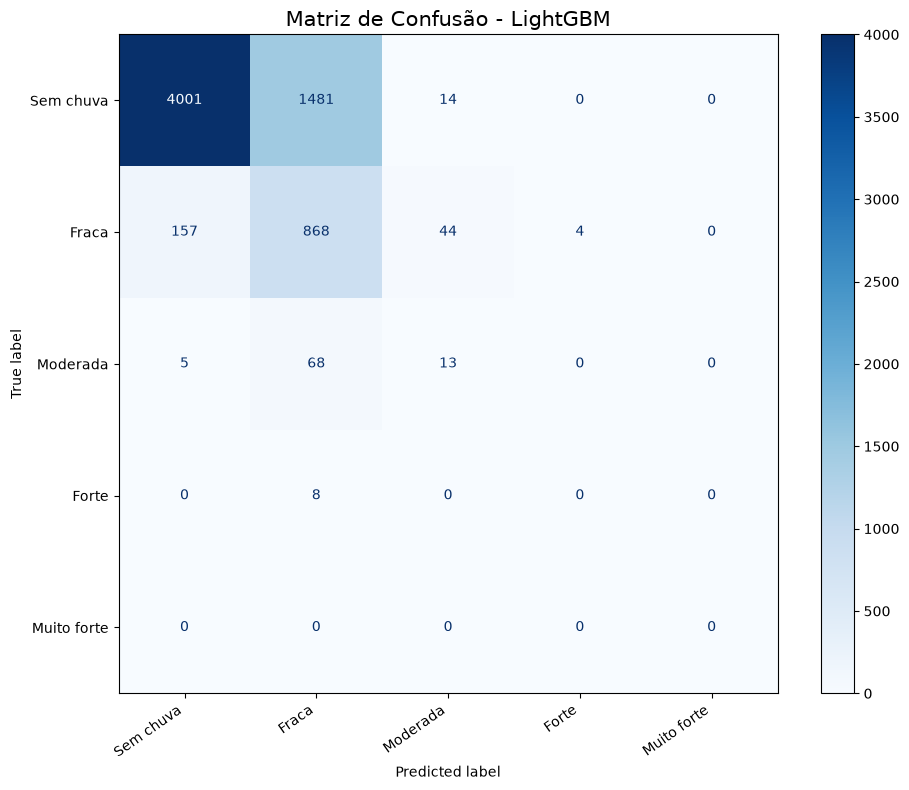

In [58]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=[
        "Sem chuva",
        "Fraca",
        "Moderada",
        "Forte",
        "Muito forte"
    ]
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=True
)

plt.title("Matriz de Confusão - LightGBM", fontsize=15)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


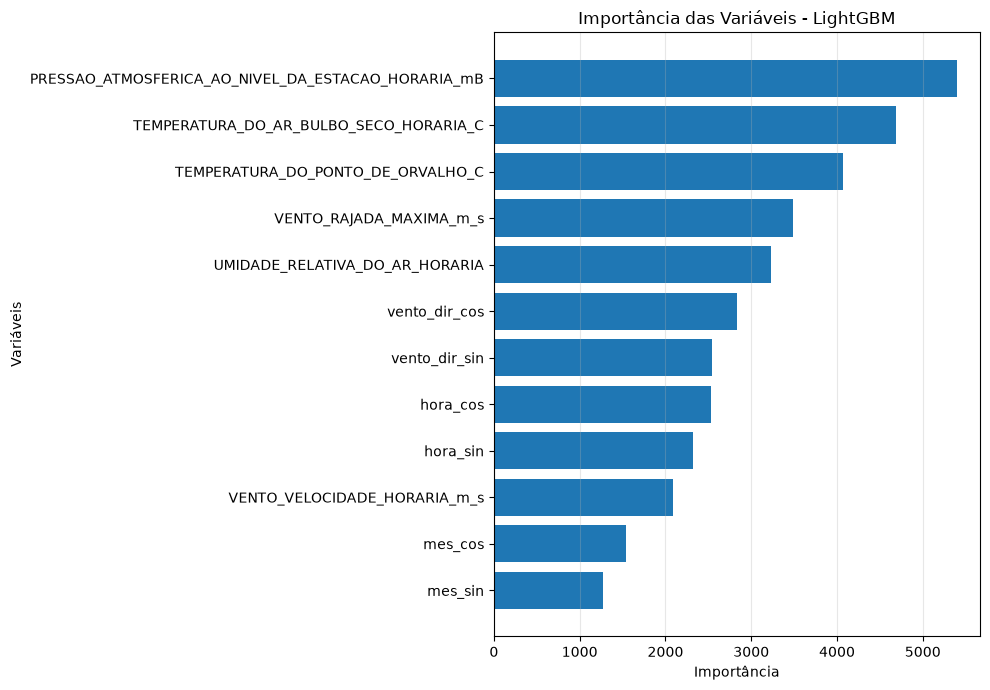

In [59]:
importancias = pd.Series(
    modelo_lgbm.feature_importances_,
    index=X_train_lgbm.columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 7))

plt.barh(importancias.index, importancias.values)

plt.title("Importância das Variáveis - LightGBM")
plt.xlabel("Importância")
plt.ylabel("Variáveis")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [60]:

resultados_lgbm = pd.DataFrame({
    "Modelo": ["LightGBM"],
    "Acurácia": [acuracia],
    "Acurácia balanceada": [acuracia_balanceada]
})

resultados_lgbm


,Modelo,Acurácia,Acurácia balanceada
0,LightGBM,0.732703,0.422023


## Considerações Finais

O desenvolvimento do modelo passou pela preparação dos dados, seleção das variáveis, criação das classes de chuva e treinamento do LightGBM. Durante esse processo, foram feitos ajustes para tratar os dados e adequá-los ao modelo.

Nos resultados, o modelo alcançou 73% de acurácia, mas apresentou desempenhos diferentes entre as classes. Conseguiu identificar melhor os registros sem chuva e de chuva fraca, porém teve dificuldades com as chuvas moderadas e fortes, principalmente pela quantidade reduzida de exemplos dessas categorias.

Com isso, foi possível perceber que o modelo ainda precisa de melhorias, especialmente em relação ao desequilíbrio dos dados. Mesmo assim, o desenvolvimento permitiu aplicar na prática os conceitos de classificação e compreender melhor as dificuldades de utilizar aprendizado de máquina com dados meteorológicos.